# MaxCut — VQE (PennyLane)

Mismo Hamiltoniano de coste que QAOA ($C=\sum \tfrac12(1-Z_i Z_j)$).
Ansatz hardware-efficient (capas $R_Y$ + CNOT en anillo) + COBYLA; se toma el
bitstring de menor energía (máximo corte) tras muestreo.


In [1]:
import itertools
import json
import math
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np

import pennylane as qml
from pennylane import numpy as pnp
from scipy.optimize import minimize


In [2]:
def resolve_maxcut_dir() -> Path:
    for base in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
        root = base / "Notebooks" / "Optimization" / "MaxCutOptimization"
        if root.is_dir():
            return root
    return Path.cwd().resolve() / "Notebooks" / "Optimization" / "MaxCutOptimization"


MAXCUT_DIR = resolve_maxcut_dir()
INSTANCE_PATH = MAXCUT_DIR / "instance" / "hamlib_maxcut.json"
METRICS_DIR = MAXCUT_DIR / "metrics"
METRICS_DIR.mkdir(parents=True, exist_ok=True)

instance = json.loads(INSTANCE_PATH.read_text())
n = int(instance["n"])
edges = [tuple(e) for e in instance["edges"]]
OPTIMAL_CUT = int(instance["optimal_cut"])
OPTIMAL_BITS = list(instance["optimal_bits"])
nodes = list(range(n))

print(
    f"HamLib MaxCut | index={instance['hamlib_index']} id={instance['hamlib_id']} "
    f"n={n} |E|={len(edges)} optimal_cut={OPTIMAL_CUT}"
)
print("Fuente:", instance["url"])
print("Demo QAOA:", instance["demo_ref"])


def cut_value(bits) -> int:
    return int(sum(1 for a, b in edges if bits[a] != bits[b]))


def is_success(bits) -> bool:
    return cut_value(bits) == OPTIMAL_CUT


def save_maxcut_metrics(payload: dict, filename: str):
    path = METRICS_DIR / filename
    path.write_text(json.dumps(payload, indent=2))
    print("Saved:", path)
    return path


HamLib MaxCut | index=8 id=circ_offsets-1-2 n=6 |E|=12 optimal_cut=8
Fuente: https://pennylane.ai/datasets/hamlib-maxcut
Demo QAOA: https://pennylane.ai/demos/tutorial_qaoa_maxcut


## VQE multi-seed


In [3]:
N_RUNS = 5
REPS = 2
COBYLA_MAXITER = 80
SHOTS = 500
RESTARTS = 3

dev = qml.device("default.qubit", wires=n)
n_params = n * REPS  # RY per wire per layer

def ansatz(params):
    idx = 0
    for r in range(REPS):
        for w in range(n):
            qml.RY(params[idx], wires=w)
            idx += 1
        for w in range(n):
            qml.CNOT(wires=[w, (w + 1) % n])

@qml.qnode(dev)
def expval_zz(params):
    ansatz(params)
    zz = qml.sum(*(qml.Z(a) @ qml.Z(b) for a, b in edges))
    return qml.expval(zz)

def expval_cost(params):
    # minimize -C = -0.5*(|E| - <ZZ sum>)
    return -0.5 * (len(edges) - float(expval_zz(params)))

@qml.qnode(dev)
def sample_bits(params):
    ansatz(params)
    return qml.sample(wires=range(n))


def run_vqe(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    t0 = time.perf_counter()
    best_params, best_e = None, 1e9
    evals = 0
    for r in range(RESTARTS):
        x0 = 0.1 * np.random.randn(n_params)
        def fun(x):
            nonlocal evals
            evals += 1
            return float(expval_cost(pnp.array(x, requires_grad=False)))
        res = minimize(fun, x0, method="COBYLA", options={"maxiter": COBYLA_MAXITER})
        if res.fun < best_e:
            best_e, best_params = float(res.fun), res.x
    samples = qml.set_shots(sample_bits, shots=SHOTS)(pnp.array(best_params, requires_grad=False))
    # pick most frequent
    as_tuples = [tuple(int(b) for b in row) for row in np.array(samples)]
    counts = {}
    for t in as_tuples:
        counts[t] = counts.get(t, 0) + 1
    bits = list(max(counts, key=counts.get))
    # also check best cut among unique samples
    best_bits = bits
    best_cut = cut_value(bits)
    for t in counts:
        c = cut_value(list(t))
        if c > best_cut:
            best_cut, best_bits = c, list(t)
    elapsed = time.perf_counter() - t0
    return {
        "seed": seed,
        "bits": best_bits,
        "cut": float(best_cut),
        "success": bool(best_cut == OPTIMAL_CUT),
        "time_s": float(elapsed),
        "energy_evals": evals,
    }

rows = []
for seed in range(N_RUNS):
    out = run_vqe(seed)
    rows.append(out)
    print(f"seed={seed} success={out['success']} cut={out['cut']} time={out['time_s']:.2f}s")

cuts = np.array([r["cut"] for r in rows], dtype=float)
times = np.array([r["time_s"] for r in rows], dtype=float)
success_rate = float(np.mean([r["success"] for r in rows]))

payload = {
    "problem": "maxcut",
    "solver": "vqe",
    "family": "quantum_inspired",
    "protocol": {
        "n_runs": N_RUNS,
        "ansatz": "RY_ring_CNOT",
        "reps": REPS,
        "restarts": RESTARTS,
        "shots": SHOTS,
        "cobyla_maxiter": COBYLA_MAXITER,
        "backend": "pennylane_default.qubit",
        "sense": "maximize_cut",
        "hamlib_index": instance["hamlib_index"],
        "hamlib_id": instance["hamlib_id"],
    },
    "instance": {"n": n, "edges": [list(e) for e in edges], "source": instance["source"]},
    "quality": {
        "optimal_cost": float(OPTIMAL_CUT),
        "optimal_bits": OPTIMAL_BITS,
        "cost_mean": float(np.mean(cuts)),
        "cost_best": float(np.max(cuts)),
        "gap_mean": float(np.mean(OPTIMAL_CUT - cuts)),
    },
    "success_rate": success_rate,
    "time_s": {"mean": float(np.mean(times)), "std": float(np.std(times)), "total": float(np.sum(times))},
    "effort": {"energy_evals_mean": float(np.mean([r["energy_evals"] for r in rows]))},
    "runs": rows,
}
save_maxcut_metrics(payload, "vqe_maxcut.json")
print(f"success_rate={success_rate:.3f}")


seed=0 success=True cut=8.0 time=0.98s
seed=1 success=True cut=8.0 time=0.98s
seed=2 success=True cut=8.0 time=0.97s
seed=3 success=True cut=8.0 time=0.98s
seed=4 success=True cut=8.0 time=0.99s
Saved: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Optimization/MaxCutOptimization/metrics/vqe_maxcut.json
success_rate=1.000


## Storytelling plots

Figuras para documento/slides → `figures/`.


Saved figure: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Optimization/MaxCutOptimization/figures/instance_maxcut_graph.png


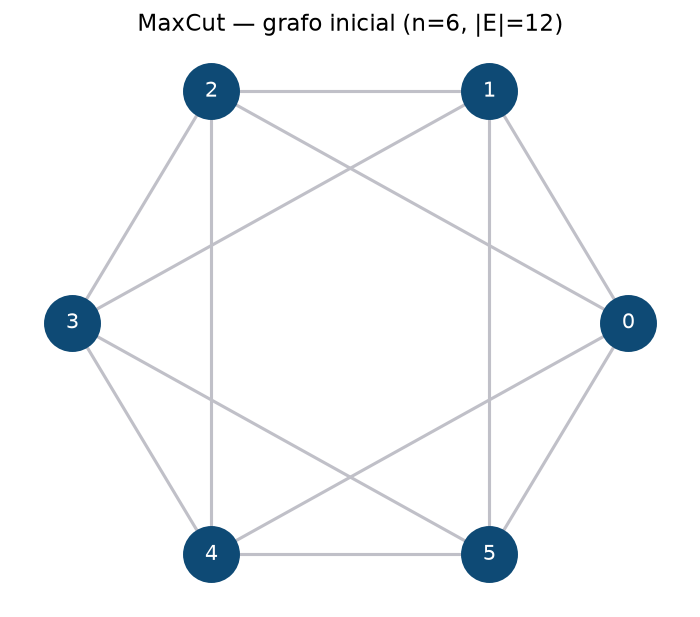

Saved figure: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Optimization/MaxCutOptimization/figures/vqe_maxcut_cut.png


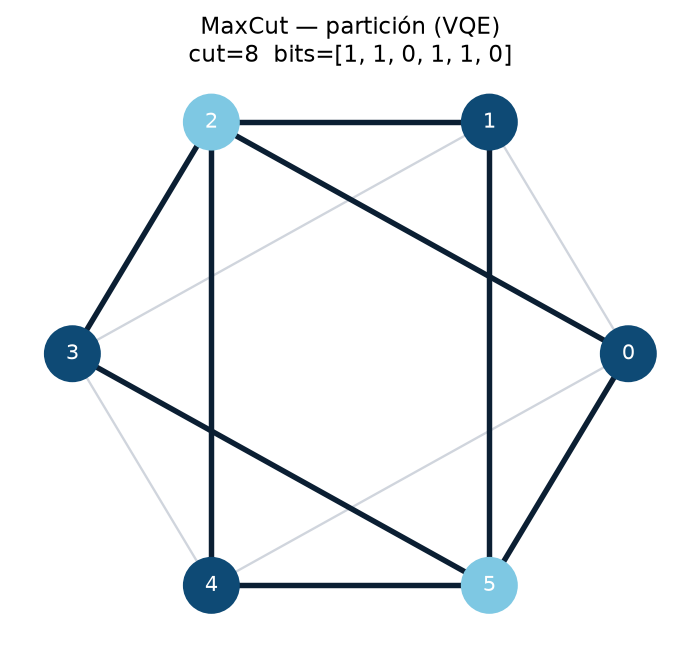

PosixPath('/Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Optimization/MaxCutOptimization/figures/vqe_maxcut_cut.png')

In [4]:
# --- storytelling plots (auto) ---
from pathlib import Path
import sys
import numpy as np

for _base in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    _lib = _base / "Notebooks" / "lib"
    if (_lib / "storytelling.py").is_file():
        _s = str(_lib)
        if _s not in sys.path:
            sys.path.insert(0, _s)
        break
else:
    raise FileNotFoundError("Notebooks/lib/storytelling.py not found")

import importlib
import storytelling as _storytelling
importlib.reload(_storytelling)
from storytelling import (
    resolve_figures_dir,
    plot_maxcut_instance, plot_maxcut_partition,
)

figures_dir = resolve_figures_dir("Optimization", "MaxCutOptimization")
plot_maxcut_instance(n, edges, figures_dir, stem="instance")
_bits = None
if "payload" in globals() and payload.get("runs"):
    _runs = [r for r in payload["runs"] if r.get("bits") is not None]
    if _runs:
        # MaxCut: higher cut is better
        _bits = max(_runs, key=lambda r: float(r.get("cut", r.get("cost", -1e18)))).get("bits")
if _bits is None and "best_b" in globals() and best_b is not None:
    _bits = best_b
if _bits is None and "bits" in globals() and isinstance(bits, (list, tuple)):
    _bits = bits
if _bits is None and "OPTIMAL_BITS" in globals():
    _bits = OPTIMAL_BITS
if _bits is None:
    raise RuntimeError("No MaxCut bits found for storytelling plot")
plot_maxcut_partition(n, edges, _bits, figures_dir, stem="vqe", title="VQE")
